# Query, Key, Value 구현

Query, Key, Value는 행렬로 가중치를 나타낼 수 있다. 이에 nn.Linear로 구현할 수 있다.<br/>
또한, Query, Key, Value가 나오는 과정은 아래와 같다.

### **Raw Data**
ex) "나는 Transformer를 공부중이다."

|

### **Tokenizer**
ex) [3, 7, 8, 9, 1]

|

### **Embedding**
ex) [[0.148, 0.223, 0.227, -0.2639, 0.2263, ...],<br/>
[-0.140, 0.213, 0.207, -0.2639, 0.3473, ...],<br/>
[0.148, 0.963, 0.321, -0.2699, 0.2363, ...],<br/>
[-0.248, 0.122, 0.328, -0.1269, 0.4263, ...],<br/>
[0.188, 0.983, 0.037, -0.3769, 0.2583, ...]]

|

### **Query, Key, Value**
ex) [[□, □, □, □, □, ...],<br/>
[□, □, □, □, □,, ...],<br/>
[□, □, □, □, □,, ...],<br/>
[□, □, □, □, □,, ...],<br/>
[□, □, □, □, □,, ...]]

In [3]:
import torch, torch.nn as nn, math

# seq_len은 Embedding에 들어가는 sequence 길이
# d_model은 Embedding에 들어가는 dimension 값
seq_len, d_model, d_k = 5, 16, 16
x = torch.randn(1, seq_len, d_model)   # [batch, seq_len, d_model]

# Qeury, Key, Value Parameter는 행렬로 가중치를 정의한다.(신경망)
# 이는 nn.Linear로 구현 가능하다.
# 각 shape은 (d_model, d_k)의 행렬 가중치를 가지게 된다.
W_q = nn.Linear(d_model, d_k, bias=False)
W_k = nn.Linear(d_model, d_k, bias=False)
W_v = nn.Linear(d_model, d_k, bias=False)

# Qeury, Key, Value는 이런 Parameter를 거친 값들이다.
Q, K, V = W_q(x), W_k(x), W_v(x)
print(Q.shape, K.shape, V.shape)  # [1, 5, 16] 각각

torch.Size([1, 5, 16]) torch.Size([1, 5, 16]) torch.Size([1, 5, 16])


In [4]:
scores = Q @ K.transpose(-2, -1)     # [1, 5, 5] — 모든 단어 쌍의 내적
scores = scores / math.sqrt(d_k)      # 스케일링

print(scores.shape)  # [1, 5, 5]
# scores[0, i, j] = i번째 단어의 Query와 j번째 단어의 Key의 유사도

torch.Size([1, 5, 5])


In [5]:
# 각 단어들간의 유사도
scores

tensor([[[ 0.1046,  0.7308, -0.6597,  0.4385, -0.1909],
         [-0.3356,  0.2273, -0.0864,  0.0199, -0.0082],
         [-0.5899,  0.2390,  0.3552,  0.0494, -0.1667],
         [ 0.1129, -0.0418,  0.2634, -0.1086, -0.2258],
         [-0.7875,  0.1279, -0.2449, -0.0863, -0.4835]]],
       grad_fn=<DivBackward0>)

In [6]:
weights = torch.softmax(scores, dim=-1)   # 각 행의 합이 1(확률로 변환)
output = weights @ V                        # [1, 5, 16]

# 0번째 단어가 다른 단어들을 보는 비율
print(weights[0, 0])

# 입력과 같은 [1, 5, 16] — 문맥이 반영된 새 표현
# Embedding에서 나온 결과 벡터보다 다른 단어들까지 반영한 벡터가 나오게 됨.
print(output.shape)   

tensor([0.1826, 0.3415, 0.0850, 0.2550, 0.1359], grad_fn=<SelectBackward0>)
torch.Size([1, 5, 16])


In [7]:
# 들어오는 Q, K, V는 W_q, W_k, W_v와 Embedding 결과 값을 각각 계산한 값.
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    output = weights @ V
    
    return output, weights

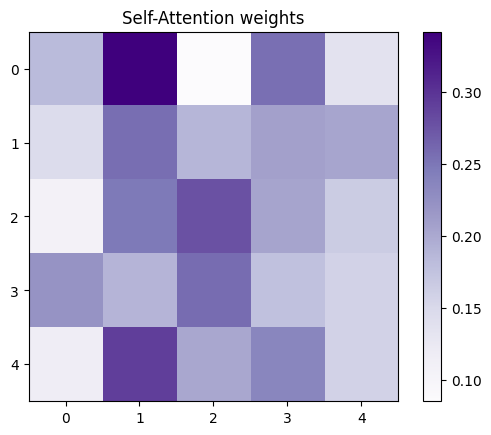

In [8]:
import matplotlib.pyplot as plt

w = weights[0].detach().numpy()   # [seq_len, seq_len]
plt.imshow(w, cmap="Purples")
# plt.xticks(range(seq_len), tokens, rotation=45)
# plt.yticks(range(seq_len), tokens)
plt.colorbar()
plt.title("Self-Attention weights")
plt.show()

In [9]:
'''
Query, Key, Value Parameter는 모두 학습하는 파라미터다.
'''

'\nQuery, Key, Value Parameter는 모두 학습하는 파라미터다.\n'

# Tokenizer -> Embedding -> Query, Key, Value까지

지금까지 배운 내용을 전부 구현해보자

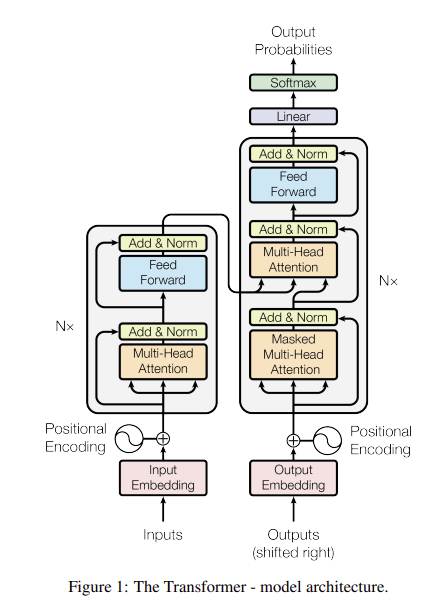

### 1. preprocessing + Vocab

In [10]:
# vocab 만드는 함수
# setences는 vocab을 만들 때 필요한 데이터
def create_vocab(sentences, special_tokens=["<pad>", "<sos>", "<eos>", "<unk>"]):
    words = sorted(set(w for s in sentences for w in s.split()))
    vocab = special_tokens + words # 특수 토큰들에 대해서도 index를 매기기 위해서 SPECIALS와 words를 합침.
    stoi = {w: i for i, w in enumerate(vocab)}
    itos = {i: w for i, w in enumerate(vocab)}

    return words, vocab, stoi, itos

In [11]:
import torch

# 앞에서 encode 함수는 string에 대해서 처리
def encode(sentence, stoi):
    # 예외처리가 동작하면서 이전에 없던 값들이면 <unk>로 대체.
    ids = [stoi.get(w, stoi["<unk>"]) for w in sentence.split()]
    return [stoi["<sos>"]] + ids + [stoi["<eos>"]]

# 실제로는 리스트 형태로 들어옴(텐서)
# 이에 맞춰서 preprocessing 함수를 새로 선언
def preprocessing(text, stoi, padding_size=10, padding_token=0):
    input_tokens = []
    for sentence in text:
        # 우선 각 토큰들을 encoding
        encoded_sentence = encode(sentence, stoi)

        # embedding에 들어갈 때는 모든 데이터의 크기가 동일해야 하므로, padding적용
        encoded_padded_sentence = encoded_sentence + [padding_token] * (padding_size - len(encoded_sentence))

        input_tokens.append(encoded_padded_sentence)

    return torch.tensor(input_tokens) # tensor 적용은 반드시 해야함.

### 2. Embedding

In [12]:
import torch.nn as nn

vocab_size = 50
embed_dim = 16

# embedding layer
embedding = nn.Embedding(vocab_size, embed_dim)

### 3. Query, Key, Value

In [13]:
# 들어오는 Q, K, V는 W_q, W_k, W_v와 Embedding 결과 값을 각각 계산한 값.
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    output = weights @ V
    
    return output, weights

### 4. Model 생성

In [14]:
import torch.nn as nn

class TSModel(nn.Module):
    def __init__(self, vocab_size=50, embed_dim=16):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim

        # Embedding
        self.embed_layer = nn.Embedding(vocab_size, embed_dim)

        # Qeury, Key, Value Parameter
        self.W_q = nn.Linear(vocab_size, embed_dim)
        self.W_k = nn.Linear(vocab_size, embed_dim)
        self.W_v = nn.Linear(vocab_size, embed_dim)

    def forward(self, x):
        # Embedding
        embeded_x = self.embed_layer(x)

        # Query, Key, Value 값 계산
        Q = self.embed_layer(x)
        K = self.embed_layer(x)
        V = self.embed_layer(x)

        output, weights = scaled_dot_product_attention(Q, K, V, mask=None)

        return output, weights

### 5. Data 넣어보기

In [15]:
# 들어갈 Raw Data
text = ["안녕", "나는 오늘 밥을 먹었어."]

# vocab 사전을 만들기 위한 데이터
sentences = ["나는 밥을 먹었다", "너는 밥을 먹었니"]

# 특수 토큰: 패딩, 문장 시작/끝, 미등록 단어
special_tokens = ["<pad>", "<sos>", "<eos>", "<unk>"]

In [16]:
# vocab 만들기
words, vocab, stoi, itos = create_vocab(sentences, special_tokens)

x = preprocessed_text = preprocessing(text, stoi)

# Query, Key, Value를 만드는 모델 생성
model = TSModel(vocab_size=50, embed_dim=16)

# 최종 반환값
# output이 실제 전체 반환값
# weights는 Query와 Key에 대한 Score까지만.
output, weights = model(x)

In [17]:
print(f"Output Shape: {output.shape}, Weight Shape(Scores): {weights.shape}")

Output Shape: torch.Size([2, 10, 16]), Weight Shape(Scores): torch.Size([2, 10, 10])


In [18]:
output

tensor([[[-0.1825,  0.1577, -0.0107, -0.0626, -0.0311,  0.2038, -0.0521,
          -0.6044,  0.3545,  0.4089, -1.5691,  0.2171,  0.8299,  0.6998,
           0.3180, -0.6393],
         [ 0.0694,  0.2098,  0.6403, -0.3575, -0.3551,  0.0758,  0.1414,
           0.3282,  0.1731,  0.7652, -0.4431,  0.6078, -0.1047,  0.6617,
           0.3073, -0.4739],
         [-0.1736,  0.3560,  0.5381,  0.8657, -0.6255,  0.1089,  0.0697,
          -0.8810,  0.2027,  0.2973, -0.9572,  0.5322,  0.2702,  1.3616,
           0.2329, -1.7109],
         [ 0.3822,  0.6212,  1.0701,  2.1721, -1.0343,  0.2838, -0.1811,
          -1.6442, -0.4753,  0.2924, -0.8659,  0.7529,  0.3410,  2.2027,
           0.3200, -2.9269],
         [ 0.3822,  0.6212,  1.0701,  2.1721, -1.0343,  0.2838, -0.1811,
          -1.6442, -0.4753,  0.2924, -0.8659,  0.7529,  0.3410,  2.2027,
           0.3200, -2.9269],
         [ 0.3822,  0.6212,  1.0701,  2.1721, -1.0343,  0.2838, -0.1811,
          -1.6442, -0.4753,  0.2924, -0.8659,  0.752

In [19]:
weights

tensor([[[5.6426e-01, 5.1410e-02, 1.1053e-01, 3.9115e-02, 3.9115e-02,
          3.9115e-02, 3.9115e-02, 3.9115e-02, 3.9115e-02, 3.9115e-02],
         [9.3624e-02, 5.5701e-01, 1.1174e-01, 3.3946e-02, 3.3946e-02,
          3.3946e-02, 3.3946e-02, 3.3946e-02, 3.3946e-02, 3.3946e-02],
         [1.1320e-01, 6.2840e-02, 2.7141e-01, 7.8936e-02, 7.8936e-02,
          7.8936e-02, 7.8936e-02, 7.8936e-02, 7.8936e-02, 7.8936e-02],
         [1.7474e-04, 8.3271e-05, 3.4431e-04, 1.4277e-01, 1.4277e-01,
          1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01],
         [1.7474e-04, 8.3271e-05, 3.4431e-04, 1.4277e-01, 1.4277e-01,
          1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01],
         [1.7474e-04, 8.3271e-05, 3.4431e-04, 1.4277e-01, 1.4277e-01,
          1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01],
         [1.7474e-04, 8.3271e-05, 3.4431e-04, 1.4277e-01, 1.4277e-01,
          1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01, 1.4277e-01],
         [1.7

# Attention만으로 감정 분류 학습 시켜보기

Naver에서 제공한 영화 리뷰 감정 분류 데이터셋(NSMC)
* 0이 부정
* 1이 긍정

### 1. Load Data

In [20]:
import pandas as pd

train_url = "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt"
test_url  = "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt"

train_df = pd.read_csv(train_url, sep="\t")
test_df  = pd.read_csv(test_url, sep="\t")

print(train_df.head())

         id                                           document  label
0   9976970                                아 더빙.. 진짜 짜증나네요 목소리      0
1   3819312                  흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나      1
2  10265843                                  너무재밓었다그래서보는것을추천한다      0
3   9045019                      교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정      0
4   6483659  사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...      1


In [21]:
# NAN값 제거
train_df = train_df.dropna(subset=["document"])
test_df  = test_df.dropna(subset=["document"])

train_texts, train_labels = train_df["document"].tolist(), train_df["label"].tolist()
test_texts, test_labels   = test_df["document"].tolist(), test_df["label"].tolist()

In [22]:
# 학습에 사용될 texts들
train_texts[:10]

['아 더빙.. 진짜 짜증나네요 목소리',
 '흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나',
 '너무재밓었다그래서보는것을추천한다',
 '교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정',
 '사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 던스트가 너무나도 이뻐보였다',
 '막 걸음마 뗀 3세부터 초등학교 1학년생인 8살용영화.ㅋㅋㅋ...별반개도 아까움.',
 '원작의 긴장감을 제대로 살려내지못했다.',
 '별 반개도 아깝다 욕나온다 이응경 길용우 연기생활이몇년인지..정말 발로해도 그것보단 낫겟다 납치.감금만반복반복..이드라마는 가족도없다 연기못하는사람만모엿네',
 '액션이 없는데도 재미 있는 몇안되는 영화',
 '왜케 평점이 낮은건데? 꽤 볼만한데.. 헐리우드식 화려함에만 너무 길들여져 있나?']

In [23]:
# 테스트에 사용될 texts들
test_texts[:10]

['굳 ㅋ',
 'GDNTOPCLASSINTHECLUB',
 '뭐야 이 평점들은.... 나쁘진 않지만 10점 짜리는 더더욱 아니잖아',
 '지루하지는 않은데 완전 막장임... 돈주고 보기에는....',
 '3D만 아니었어도 별 다섯 개 줬을텐데.. 왜 3D로 나와서 제 심기를 불편하게 하죠??',
 '음악이 주가 된, 최고의 음악영화',
 '진정한 쓰레기',
 '마치 미국애니에서 튀어나온듯한 창의력없는 로봇디자인부터가,고개를 젖게한다',
 '갈수록 개판되가는 중국영화 유치하고 내용없음 폼잡다 끝남 말도안되는 무기에 유치한cg남무 아 그립다 동사서독같은 영화가 이건 3류아류작이다',
 '이별의 아픔뒤에 찾아오는 새로운 인연의 기쁨 But, 모든 사람이 그렇지는 않네..']

### 2. Vocab 생성

In [24]:
# vocab 사전을 만들기 위한 데이터
sentences = train_texts

# 특수 토큰: 패딩, 문장 시작/끝, 미등록 단어
special_tokens = ["<pad>", "<sos>", "<eos>", "<unk>"]

words, vocab, stoi, itos = create_vocab(sentences[:10000], special_tokens)

In [25]:
len(vocab)

40303

### 3. Model 생성

In [26]:
class TSModel(nn.Module):
    def __init__(self, vocab_size=50000, embed_dim=16, num_classes=2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim

        # Embedding
        self.embed_layer = nn.Embedding(vocab_size, embed_dim)

        # Qeury, Key, Value Parameter
        self.W_q = nn.Linear(100, embed_dim)
        self.W_k = nn.Linear(100, embed_dim)
        self.W_v = nn.Linear(100, embed_dim)

        # 감정 분류(클래스가 2개)이므로 마지막 feed forward만 넣어주면 우리가 원하는 모델을 만들 수 있음.
        self.feed_forward = nn.Linear(embed_dim, num_classes)
        self.act = nn.Softmax(dim=-1)

    def forward(self, x):
        # Embedding
        embeded_x = self.embed_layer(x)

        # Query, Key, Value 값 계산
        Q = self.embed_layer(x)
        K = self.embed_layer(x)
        V = self.embed_layer(x)

        output, weights = scaled_dot_product_attention(Q, K, V, mask=None)

        # 긍정인지 부정인지 확인
        x = self.feed_forward(output)
        # 확률값으로 변환
        x = self.act(x)

        return x

In [27]:
# 감정 분류 모델 생성
set_model = TSModel(vocab_size=len(vocab))

### 4. DataSet과 DataLoader 생성

In [28]:
from torch.utils.data import Dataset, DataLoader

# 여기서 transform은 preprocessing을 의미
class NSMC_Dataset(Dataset):
    def __init__(self, texts, labels, stoi=None, transform=None):
        self.texts = texts
        self.labels = labels
        self.stoi = stoi
        self.transform = transform

    def __len__(self):
        # 원래 tensor로 들어오면 shape이나 size 함수로 선언 가능하지만, 리스트가 들어오므로 len으로 호출
        return len(self.texts)

    def __getitem__(self, idx):
        batch_texts = self.texts[idx]
        batch_labels = self.labels[idx]

        if self.transform:
            batch_texts = self.transform([batch_texts], stoi, padding_size=50)

        return batch_texts, batch_labels

In [29]:
train_dataset = NSMC_Dataset(train_texts, train_labels, stoi, preprocessing)
test_dataset = NSMC_Dataset(test_texts, test_labels, stoi, preprocessing)

In [30]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [31]:
next(iter(train_dataloader))[0].shape

torch.Size([32, 1, 50])

In [32]:
output = set_model(next(iter(train_dataloader))[0])

In [33]:
output.shape

torch.Size([32, 1, 50, 2])

### 5. 학습

In [34]:
import torch
import torch.nn as nn
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score

# GPU 사용 가능하면 GPU, 아니면 CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 위에서 이미 만들어둔 것들을 그대로 사용
# - set_model: TSModel(vocab_size=50000, embed_dim=16, num_classes=2)
# - train_dataloader, test_dataloader: NSMC 데이터를 stoi로 인코딩한 DataLoader
set_model = set_model.to(device)

# set_model의 forward가 마지막에 Softmax(dim=-1)로 "확률"을 반환하므로,
# 내부에서 log_softmax를 또 적용하는 CrossEntropyLoss 대신 NLLLoss(log(확률))를 사용.
criterion = nn.NLLLoss()
optimizer = torch.optim.Adam(set_model.parameters(), lr=1e-3)

# tqdm 갱신 주기 (20 batch마다 한 번씩만 postfix 갱신)
LOG_INTERVAL = 20

# Train 및 Eval 로직
num_epochs = 5
for epoch in range(num_epochs):
    # 1. model train
    set_model.train()
    train_loss = 0.0
    train_preds_all, train_labels_all = [], []

    with tqdm(train_dataloader, desc=f"[Epoch {epoch+1}/{num_epochs}] Train", leave=False) as train_bar:
        for batch_idx, (texts, labels) in enumerate(train_bar):
            texts, labels = texts.to(device, non_blocking=True), labels.to(device, non_blocking=True)

            # 1-1. model 예측
            # set_model(texts) shape: [B, 1, seq_len, num_classes] (토큰별 클래스 확률)
            # -> 문장 하나당 확률 하나로 만들기 위해 seq_len 축을 평균으로 pooling
            probs = set_model(texts).squeeze(1).mean(dim=1)  # [B, num_classes]

            # 1-2. loss function 계산
            loss = criterion(torch.log(probs.clamp_min(1e-9)), labels)

            # 1-3. 이전 기울기 초기화
            optimizer.zero_grad()

            # 1-4. 역전파(backpropagation) -> 기울기 계산
            loss.backward()

            # 1-5. 파라미터 업데이트
            optimizer.step()

            train_loss += loss.item() * texts.size(0)
            train_preds_all.extend(probs.argmax(dim=1).cpu().tolist())
            train_labels_all.extend(labels.cpu().tolist())

            # 20 batch마다 한 번씩 loss/accuracy 갱신
            if (batch_idx + 1) % LOG_INTERVAL == 0:
                train_accuracy = accuracy_score(train_labels_all, train_preds_all)
                train_bar.set_postfix(loss=f"{loss.item():.4f}", accuracy=f"{train_accuracy:.2%}")

    train_loss /= len(train_dataloader.dataset)
    train_accuracy = accuracy_score(train_labels_all, train_preds_all)

    # 2. model eval
    set_model.eval()
    eval_preds_all, eval_labels_all = [], []
    accuracy = 0.0

    with torch.no_grad(), tqdm(test_dataloader, desc=f"[Epoch {epoch+1}/{num_epochs}] Eval", leave=False) as eval_bar:
        for batch_idx, (texts, labels) in enumerate(eval_bar):
            texts, labels = texts.to(device, non_blocking=True), labels.to(device, non_blocking=True)

            probs = set_model(texts).squeeze(1).mean(dim=1)
            eval_preds_all.extend(probs.argmax(dim=1).cpu().tolist())
            eval_labels_all.extend(labels.cpu().tolist())

            # 20 batch마다 한 번씩 accuracy 갱신
            if (batch_idx + 1) % LOG_INTERVAL == 0:
                accuracy = accuracy_score(eval_labels_all, eval_preds_all)
                eval_bar.set_postfix(accuracy=f"{accuracy:.2%}")

    accuracy = accuracy_score(eval_labels_all, eval_preds_all)

    print(f"epoch {epoch+1}/{num_epochs} | train_loss {train_loss:.4f} | train_accuracy {train_accuracy:.2%} | accuracy {accuracy:.2%}")

# 모델 저장
model_path = "ts_model_nsmc.pth"
torch.save(set_model.state_dict(), model_path)
print(f"모델 저장 완료: {model_path}")

Using device: cuda


[Epoch 1/5] Train:   0%|          | 0/4688 [00:00<?, ?it/s]

[Epoch 1/5] Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

epoch 1/5 | train_loss 0.6696 | train_accuracy 60.49% | accuracy 69.51%


[Epoch 2/5] Train:   0%|          | 0/4688 [00:00<?, ?it/s]

[Epoch 2/5] Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

... (6 outputs left out)

epoch 4/5 | train_loss 0.4450 | train_accuracy 77.46% | accuracy 76.28%


[Epoch 5/5] Train:   0%|          | 0/4688 [00:00<?, ?it/s]

[Epoch 5/5] Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

epoch 5/5 | train_loss 0.4258 | train_accuracy 78.42% | accuracy 76.06%
모델 저장 완료: ts_model_nsmc.pth


### 6. 예측

실제 모델은 당연히 숫자값들에 대해 추론을 하지만, 여기서는 한국말이 나오면 그대로 나오도록 하는 함수를 작성

In [43]:
def predict(text, stoi, padding_size=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    preprocessed_text = preprocessing([text], stoi=stoi, padding_size=padding_size)
    preprocessed_text = preprocessed_text.to(device)
    
    probs = set_model(preprocessed_text).squeeze(1).mean(dim=1)

    pred = probs.argmax(dim=-1).item()

    itos = ["부정", "긍정"]

    return itos[pred]

In [48]:
pred = predict("이거 좋다.", stoi, padding_size=50)

In [49]:
while True:
    text = input("🫠 텍스트를 입력하세요: ")
    if text == "exit":
        break

    pred = predict(text, stoi, padding_size=50)

    print(f"당신이 하시는 말씀은 {pred}적인 어투입니다 !")

당신이 하시는 말씀은 부정적인 어투입니다 !
당신이 하시는 말씀은 부정적인 어투입니다 !
당신이 하시는 말씀은 긍정적인 어투입니다 !
당신이 하시는 말씀은 부정적인 어투입니다 !
당신이 하시는 말씀은 긍정적인 어투입니다 !
당신이 하시는 말씀은 부정적인 어투입니다 !
당신이 하시는 말씀은 부정적인 어투입니다 !
당신이 하시는 말씀은 부정적인 어투입니다 !
